# NFIP claims 2020–2025: Feature selection

**DSC 411/511, Semester Project** · Venkat Repaka, Ritik Gaire · follows `01_EDA_NFIP_claims.ipynb`

The EDA notebook decided which columns are *usable* (types, missingness, duplicates, leakage, imputation). This notebook decides which of the usable columns are *worth keeping* for each research question, and proves the choice on data the selection never saw.

| RQ | Target | Rows | Metric |
|---|---|---|---|
| **RQ1 Regression** | `log_paid_building` = log1p(building payment) | paid claims only (the $0 / paid split is a separate question) | R², RMSE (log), MAE in $ |
| **RQ2 Classification** | `high_severity` = building damage ≥ train 80th percentile | claims with a usable damage figure | PR-AUC (imbalanced), ROC-AUC |
| **RQ3 Clustering + PCA** | none (unsupervised) | all claims | redundancy and variance only (Section 9) |

**Three families of selection methods are compared, then combined:**

| Family | Idea | Methods used here |
|---|---|---|
| **Filter** | Score each feature on its own, without a model | variance, Spearman / Cramér's V redundancy, VIF, univariate association with the target, mutual information |
| **Embedded** | The model selects while it trains | L1 (Lasso / L1-logistic), random-forest impurity importance |
| **Wrapper / model-agnostic** | Search subsets with a model and a validation score | permutation importance on a validation year, RFECV with year-grouped CV |

**Rules that keep the selection honest**
1. **The test years (2024–25) are never used to choose features.** Selection uses the training years only: models are fit on **2020–2022** and validated on **2023** (a time-ordered hold-out), and RFECV uses **leave-one-year-out** CV within 2020–2023.
2. **Only pre-loss features are candidates** (tier A: known when the claim is reported). Section 2 shows *why*, by measuring what happens when adjuster fields and payment outcomes are allowed in.
3. Redundant features are pruned **after** ranking, so the better-ranked member of a correlated pair survives.

In [1]:
import warnings, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import VarianceThreshold, mutual_info_regression, mutual_info_classif, RFECV
from sklearn.linear_model import LassoCV, lasso_path, LogisticRegressionCV, RidgeCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
SEED = 42
rng = np.random.default_rng(SEED)

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, GRAY = "#0b0b0b", "#52514e", "#e4e3df", "#a3a29c"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=C), "font.size": 10,
})

NB_DIR = Path.cwd()
PROJECT = NB_DIR.parent if NB_DIR.name == "notebooks" else NB_DIR
EDA_OUT = PROJECT / "notebooks" / "outputs"
FIG_DIR = PROJECT / "notebooks" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG_DIR / f"fs_{name}.png", bbox_inches="tight")

d = pd.read_parquet(EDA_OUT / "nfip_claims_2020_2025_eda_clean.parquet")
FL = json.loads((EDA_OUT / "feature_lists.json").read_text())
NOMINAL, ORDINAL, BINARY, NUMERIC = FL["nominal"], FL["ordinal"], FL["binary"], FL["numeric"]
TIER_A = NOMINAL + ORDINAL + BINARY + NUMERIC
print(f"loaded {d.shape[0]:,} rows × {d.shape[1]} columns; tier-A candidates: {len(TIER_A)} "
      f"({len(NOMINAL)} nominal, {len(ORDINAL)} ordinal, {len(BINARY)} binary, {len(NUMERIC)} numeric)")

loaded 276,580 rows × 96 columns; tier-A candidates: 44 (11 nominal, 3 ordinal, 17 binary, 13 numeric)


## 1. Targets, rows and the split

In [2]:
year = d["yearOfLoss"].values
FIT = year <= 2022            # selection: fit
VAL = year == 2023            # selection: validate
TEST = year >= 2024           # final check only
paid = d["is_paid"].eq(1).values
labeled = d["high_severity"].notna().values

RQ = {
    "RQ1": dict(name="RQ1 · log building payment (paid claims)", kind="reg", rows=paid, y=d["log_paid_building"].values),
    "RQ2": dict(name="RQ2 · high severity (top 20% damage)", kind="cls", rows=labeled, y=d["high_severity"].fillna(0).astype(int).values),
}
split_tbl = pd.DataFrame({k: {"fit 2020–22": int((v["rows"] & FIT).sum()), "validate 2023": int((v["rows"] & VAL).sum()),
                              "test 2024–25": int((v["rows"] & TEST).sum())} for k, v in RQ.items()}).T
split_tbl["positive rate fit / val / test"] = ["—"] + [" / ".join(f"{RQ['RQ2']['y'][RQ['RQ2']['rows'] & m].mean():.1%}" for m in (FIT, VAL, TEST))]
split_tbl

,fit 2020–22,validate 2023,test 2024–25,positive rate fit / val / test
RQ1,103476,16270,93186,—
RQ2,121474,18876,103511,20.3% / 18.1% / 36.2%


**Distribution shift.** The share of high-severity claims jumps from about 20% in the training years to about 36% in 2024–25, the Helene and Milton years. Any model will be judged on storms that are, on average, much more destructive than the ones it learned from. **PR-AUC must be read against each period's base rate** (a random classifier's PR-AUC equals the positive rate).

### 1.1 Two encodings of the same candidates
* **Tree / MI design** (`XO`): nominal columns become integer codes (the trees split on them; mutual information treats them as discrete). This keeps **one column per original feature**, so importances are directly comparable.
* **Linear design** (`XL`): nominal → one-hot (rare levels grouped), dollar and count columns → log1p, then everything standardised. This is needed for L1 models and VIF. Coefficients are added back up per original feature.

Both encoders are **fit on the fit years only**.

In [3]:
LOGMAP = {"totalBuildingInsuranceCoverage": "log_bldg_coverage", "totalContentsInsuranceCoverage": "log_cont_coverage",
          "policyCount": "log_policy_count", "numberOfUnits": "log_num_units"}
oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(d.loc[FIT, NOMINAL].astype(str))
XO = d[TIER_A].copy()
XO[NOMINAL] = oe.transform(d[NOMINAL].astype(str))
XO = XO.astype(float)

lin_num = [LOGMAP.get(c, c) for c in ORDINAL + BINARY + NUMERIC]
ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False, drop="first").fit(d.loc[FIT, NOMINAL].astype(str))
oh = pd.DataFrame(ohe.transform(d[NOMINAL].astype(str)), columns=ohe.get_feature_names_out(NOMINAL), index=d.index)
XL_raw = pd.concat([d[lin_num].astype(float), oh], axis=1)
sc = StandardScaler().fit(XL_raw[FIT])
XL = pd.DataFrame(sc.transform(XL_raw), columns=XL_raw.columns, index=d.index)
# map every linear column back to its original feature
lin_owner = {LOGMAP.get(c, c): c for c in ORDINAL + BINARY + NUMERIC}
for col in oh.columns:
    lin_owner[col] = next(n for n in NOMINAL if col.startswith(n + "_"))
print(f"tree/MI design: {XO.shape[1]} columns   |   linear design: {XL.shape[1]} columns (one-hot, drop-first, rare→infrequent)")

tree/MI design: 44 columns   |   linear design: 104 columns (one-hot, drop-first, rare→infrequent)


## 2. Why only pre-loss features? A leakage experiment

Three nested feature sets are trained with the same gradient-boosting model on 2020–2023 and scored on 2024–25:

* **A, pre-loss.** What is known when the claim is reported: policy, building, location, date.
* **B, A + adjuster fields.** Recorded *after* inspection: building value, replacement cost, water depths, cause of damage, settlement basis. For RQ1, B also includes the adjuster's damage figure. For RQ2 it does not, because the damage figure *defines* the label.
* **LEAK, B + payment outcomes.** Net payments, "a non-payment reason exists", "a payment date exists".

If the score jumps from A to LEAK, those columns are leaking the answer.

RQ,feature set,n features,R²,RMSE (log),MAE ($),PR-AUC,ROC-AUC,base rate
RQ1,A pre-loss,44,0.326,1.217,"$62,300",,,
RQ1,B + adjuster,57,0.956,0.311,"$7,594",,,
RQ1,LEAK + payment outcomes,62,0.997,0.080,"$2,910",,,
RQ2,A pre-loss,44,,,,0.670,0.834,36.2%
RQ2,B + adjuster,56,,,,0.806,0.902,36.2%
RQ2,LEAK + payment outcomes,61,,,,0.995,0.997,36.2%


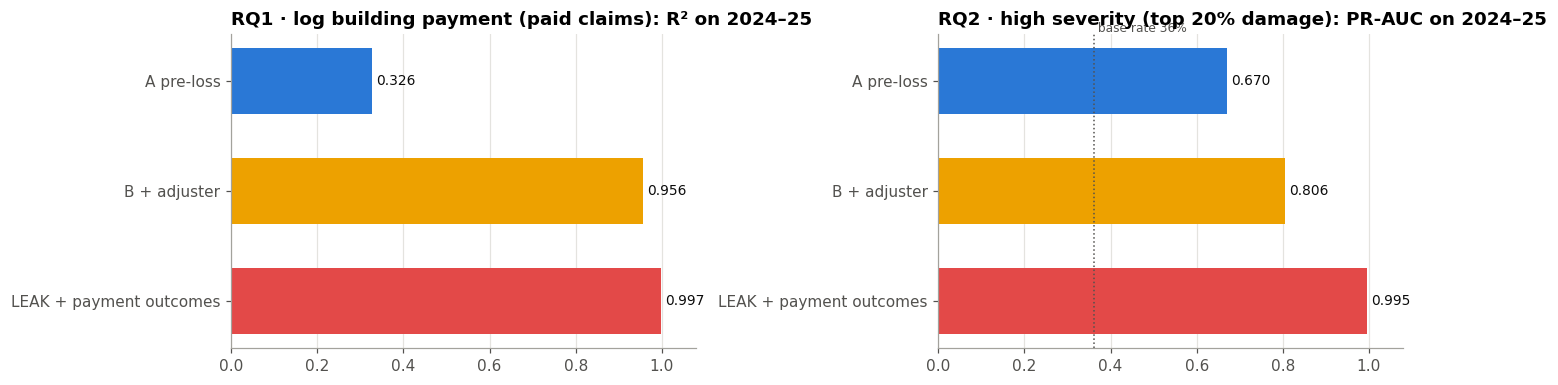

In [4]:
POST_B = ["log_bldg_value", "log_repl_cost", "waterDepth_w", "interiorWaterDepth_w", "exteriorWaterDepth_w", "waterDepth_missing",
          "interiorWaterDepth_missing", "exteriorWaterDepth_missing", "buildingPropertyValue_missing", "coverage_to_value", "cause_group",
          "replacementCostBasis"]
LEAK = FL["leakage"]
def design(cols):
    X = d[cols].copy()
    cat = [c for c in cols if c in NOMINAL or not pd.api.types.is_numeric_dtype(d[c])]
    for c_ in cat: X[c_] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(d.loc[FIT | VAL, [c_]].astype(str)).transform(d[[c_]].astype(str)).ravel()
    return X.astype(float), [X.columns.get_loc(c_) for c_ in cat]

def hgb(kind, cat_idx):
    common = dict(max_iter=400, learning_rate=0.06, max_leaf_nodes=48, min_samples_leaf=40, l2_regularization=1.0,
                  categorical_features=cat_idx or None, random_state=SEED, early_stopping=True, validation_fraction=0.1)
    return HistGradientBoostingRegressor(**common) if kind == "reg" else HistGradientBoostingClassifier(class_weight="balanced", **common)

def score(kind, y, p):
    if kind == "reg":
        return {"R²": r2_score(y, p), "RMSE (log)": np.sqrt(mean_squared_error(y, p)), "MAE ($)": mean_absolute_error(np.expm1(y), np.expm1(p))}
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p), "base rate": y.mean()}

leak_rows = []
for key, R in RQ.items():
    extra_b = ["log_bldg_damage"] if key == "RQ1" else []
    sets = {"A pre-loss": TIER_A, "B + adjuster": TIER_A + POST_B + extra_b, "LEAK + payment outcomes": TIER_A + POST_B + extra_b + LEAK}
    for sname, cols in sets.items():
        X, cat_idx = design(cols)
        tr, te = R["rows"] & ~TEST, R["rows"] & TEST
        m = hgb(R["kind"], cat_idx).fit(X[tr], R["y"][tr])
        p = m.predict(X[te]) if R["kind"] == "reg" else m.predict_proba(X[te])[:, 1]
        leak_rows.append({"RQ": key, "feature set": sname, "n features": len(cols), **score(R["kind"], R["y"][te], p)})
leak = pd.DataFrame(leak_rows)
display(leak.style.format({"R²": "{:.3f}", "RMSE (log)": "{:.3f}", "MAE ($)": "${:,.0f}", "PR-AUC": "{:.3f}", "ROC-AUC": "{:.3f}", "base rate": "{:.1%}"}, na_rep="").hide(axis="index"))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, key, met in [(ax[0], "RQ1", "R²"), (ax[1], "RQ2", "PR-AUC")]:
    t = leak[leak["RQ"] == key]
    a.barh(t["feature set"][::-1], t[met][::-1], color=[C[7], C[3], C[0]], height=0.6)
    for i, v in enumerate(t[met][::-1]): a.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9, color=INK)
    if key == "RQ2":
        br = t["base rate"].iloc[0]; a.axvline(br, color=INK2, ls=":", lw=1); a.text(br, 2.45, f" base rate {br:.0%}", fontsize=8, color=INK2)
    a.set_xlim(0, 1.08); a.set(title=f"{RQ[key]['name']}: {met} on 2024–25"); a.grid(axis="y", visible=False)
plt.tight_layout(); savefig("leakage_by_feature_set"); plt.show()

**Reading the leakage experiment.**
* **RQ1.** Adding the adjuster's damage figure lifts R² far above the pre-loss model. The damage figure is close to "the payment before deductible and limits" (ρ ≈ 0.97 in the EDA). A model that uses it is not *predicting* the payment, it is *reading* it. Adding net payments then makes the problem trivial.
* **RQ2.** Adjuster fields add real but smaller gains (water depth, value). Payment outcomes add more, because "this claim was paid" correlates with "this claim was severe".
* **Decision.** For an early-triage question ("when a claim arrives, how big will it be?"), **only tier A is legitimate**. Tier B would answer a different question ("after inspection, …"), and LEAK answers nothing. Everything below selects **within tier A**.

## 3. Filter 1: variance and redundancy
### 3.1 Near-constant features

In [5]:
vt = VarianceThreshold(threshold=0.0).fit(XO[FIT])
top_share = XO[FIT].apply(lambda s: s.value_counts(normalize=True).iloc[0])
nz = pd.DataFrame({"top value share (fit years)": top_share, "variance": XO[FIT].var()}).sort_values("top value share (fit years)", ascending=False)
NEAR_CONST = top_share[top_share >= 0.995].index.tolist()
print(f"zero-variance features: {(~vt.get_support()).sum()}  |  top value ≥ 99.5% (dropped as near-constant): {NEAR_CONST}")
nz.head(8).style.format({"top value share (fit years)": "{:.2%}", "variance": "{:.4f}"})

zero-variance features: 0  |  top value ≥ 99.5% (dropped as near-constant): ['bldg_deductible_unknown', 'cont_deductible_unknown']


,top value share (fit years),variance
cont_deductible_unknown,100.00%,0.0000
bldg_deductible_unknown,99.78%,0.0022
nonProfitIndicator,99.27%,0.0072
bldg_age_invalid_or_missing,99.13%,0.0087
no_building_cov,97.60%,0.0234
smallBusinessIndicatorBuilding,97.56%,0.0238
tenure_invalid_or_missing,96.27%,0.0359
policyCount,95.74%,91.9694


No candidate is exactly constant, because the EDA already removed those. Two flags are **near-constant in the training years** (top value ≥ 99.5%): `cont_deductible_unknown` and `bldg_deductible_unknown`. Almost every deductible was recoverable, so they are dropped here. Other skewed flags (`nonProfitIndicator`, `no_building_cov`, `smallBusinessIndicatorBuilding`, 97–99%) stay in the pool. Rarity alone is not a reason to drop: the supervised methods below decide whether they carry signal.

### 3.2 Redundant features: Spearman, Cramér's V and VIF
* **Spearman ρ** for numeric / ordinal / binary pairs (rank-based, robust to skew).
* **Cramér's V** for nominal pairs.
* **Variance inflation factor (VIF)** for the linear design: VIF = 1 / (1 − R²) of each column regressed on all the others. VIF > 10 means the column is almost a linear combination of the rest, which makes linear coefficients unstable. Trees do not care.

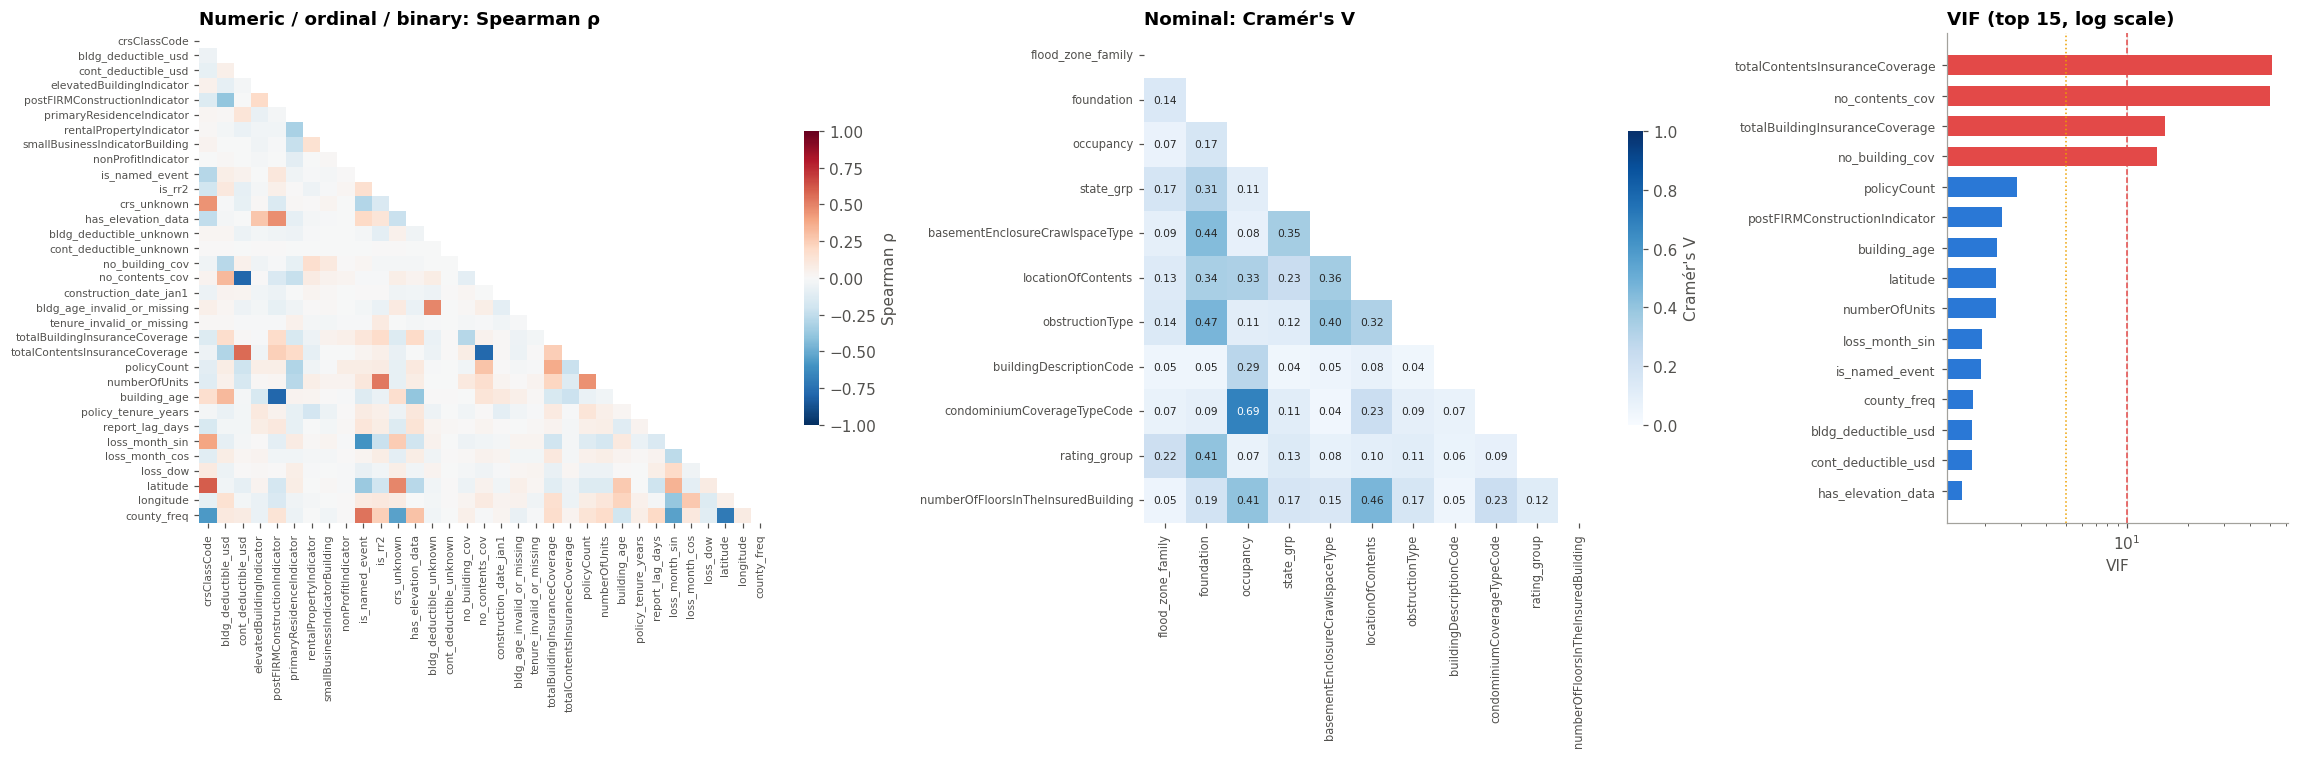

,,ρ
cont_deductible_usd,no_contents_cov,-0.796
postFIRMConstructionIndicator,building_age,-0.796
no_contents_cov,totalContentsInsuranceCoverage,-0.786
latitude,county_freq,-0.706


,,V
occupancy,condominiumCoverageTypeCode,0.685


VIF > 5: {'totalContentsInsuranceCoverage': 51.7, 'no_contents_cov': 50.4, 'totalBuildingInsuranceCoverage': 15.3, 'no_building_cov': 14.0}


binary × nominal pairs with Cramér's V ≥ 0.6:


,binary,nominal,V
86,is_rr2,rating_group,1.000
78,is_rr2,foundation,0.999
6,elevatedBuildingIndicator,obstructionType,0.979
119,bldg_deductible_unknown,rating_group,0.951
148,no_contents_cov,locationOfContents,0.819
1,elevatedBuildingIndicator,foundation,0.792
91,crs_unknown,state_grp,0.642
24,primaryResidenceIndicator,occupancy,0.625
69,is_named_event,state_grp,0.621


In [6]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * max(min(r, k) - 1, 1)))

samp = rng.choice(np.where(FIT)[0], 60000, replace=False)
num_like = ORDINAL + BINARY + NUMERIC
rho = XO.iloc[samp][num_like].corr(method="spearman")
cv_nom = pd.DataFrame(np.eye(len(NOMINAL)), index=NOMINAL, columns=NOMINAL)
for i in range(len(NOMINAL)):
    for j in range(i + 1, len(NOMINAL)):
        cv_nom.iloc[i, j] = cv_nom.iloc[j, i] = cramers_v(XO.iloc[samp][NOMINAL[i]], XO.iloc[samp][NOMINAL[j]])

corr_lin = np.corrcoef(XL.iloc[samp][lin_num].values, rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(corr_lin)), index=[lin_owner[c] for c in lin_num]).sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(21, 7), gridspec_kw={"width_ratios": [1.25, 1, 0.6]})
sns.heatmap(rho, mask=np.triu(np.ones_like(rho, dtype=bool)), cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax[0],
            cbar_kws={"shrink": 0.6, "label": "Spearman ρ"}, xticklabels=True, yticklabels=True)
ax[0].tick_params(labelsize=7); ax[0].set_title("Numeric / ordinal / binary: Spearman ρ"); ax[0].grid(False)
sns.heatmap(cv_nom, mask=np.triu(np.ones_like(cv_nom, dtype=bool)), cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            ax=ax[1], cbar_kws={"shrink": 0.6, "label": "Cramér's V"})
ax[1].tick_params(labelsize=7.5); ax[1].set_title("Nominal: Cramér's V"); ax[1].grid(False)
v = vif.head(15)[::-1]
ax[2].barh(v.index, v.values, color=[C[7] if x > 10 else (C[3] if x > 5 else C[0]) for x in v.values], height=0.65)
ax[2].axvline(10, color=C[7], ls="--", lw=1); ax[2].axvline(5, color=C[3], ls=":", lw=1)
ax[2].set_xscale("log"); ax[2].tick_params(axis="y", labelsize=8); ax[2].set(title="VIF (top 15, log scale)", xlabel="VIF"); ax[2].grid(axis="y", visible=False)
plt.tight_layout(); savefig("redundancy"); plt.show()

pairs = rho.where(np.triu(np.ones_like(rho, dtype=bool), 1)).stack().rename("ρ").to_frame()
pairs = pairs[pairs["ρ"].abs() >= 0.7].sort_values("ρ", key=abs, ascending=False)
nom_pairs = cv_nom.where(np.triu(np.ones_like(cv_nom, dtype=bool), 1)).stack().rename("V").to_frame()
nom_pairs = nom_pairs[nom_pairs["V"] >= 0.6].sort_values("V", ascending=False)
display(pairs.round(3)); display(nom_pairs.round(3))
print("VIF > 5:", vif[vif > 5].round(1).to_dict())

# binary flags vs nominal columns: neither matrix above covers these pairs, so compute Cramér's V for them too
bin_nom = pd.DataFrame([(b, n_, cramers_v(XO.iloc[samp][b], XO.iloc[samp][n_])) for b in BINARY for n_ in NOMINAL],
                       columns=["binary", "nominal", "V"])
bin_nom = bin_nom[bin_nom["V"] >= 0.6].sort_values("V", ascending=False)
print("binary × nominal pairs with Cramér's V ≥ 0.6:")
display(bin_nom.round(3))

**Redundancy found** (exact values in the tables above):
* **Coverage and its "no coverage" flag.** `no_contents_cov` ↔ `totalContentsInsuranceCoverage` ↔ `cont_deductible_usd` (|ρ| ≈ 0.8) and `no_building_cov` ↔ building coverage. These four carry the highest VIFs (14–52): each flag is almost a step function of its coverage column. A linear model needs only one of each pair.
* `postFIRMConstructionIndicator` ↔ `building_age` (ρ ≈ −0.80). Post-FIRM buildings are by definition the newer ones.
* `latitude` ↔ `county_freq` (ρ ≈ 0.7). Florida counties have both the most claims and the lowest latitudes.
* `occupancy` ↔ `condominiumCoverageTypeCode` (V ≈ 0.69). Condo coverage types belong to condo occupancies.
* **Binary flag ↔ nominal column** (last table): these pairs are not in either matrix, so Cramér's V is computed for them separately. The strongest are the elevated flag with `obstructionType` and `foundation`, and `is_rr2` with `rating_group` (RR2 is one of the groups). The exact values are printed above.

None of these is dropped yet. Section 7 keeps the **better-ranked** member of each group.

## 4. Filter 2: univariate association with the target
One number per feature, chosen to fit its type:

| Feature type | RQ1 (numeric target) | RQ2 (binary target) |
|---|---|---|
| numeric / ordinal / binary | \|Spearman ρ\| | Gini = \|2·AUC − 1\| of the feature alone |
| nominal | η (correlation ratio, from one-way ANOVA) | Cramér's V |

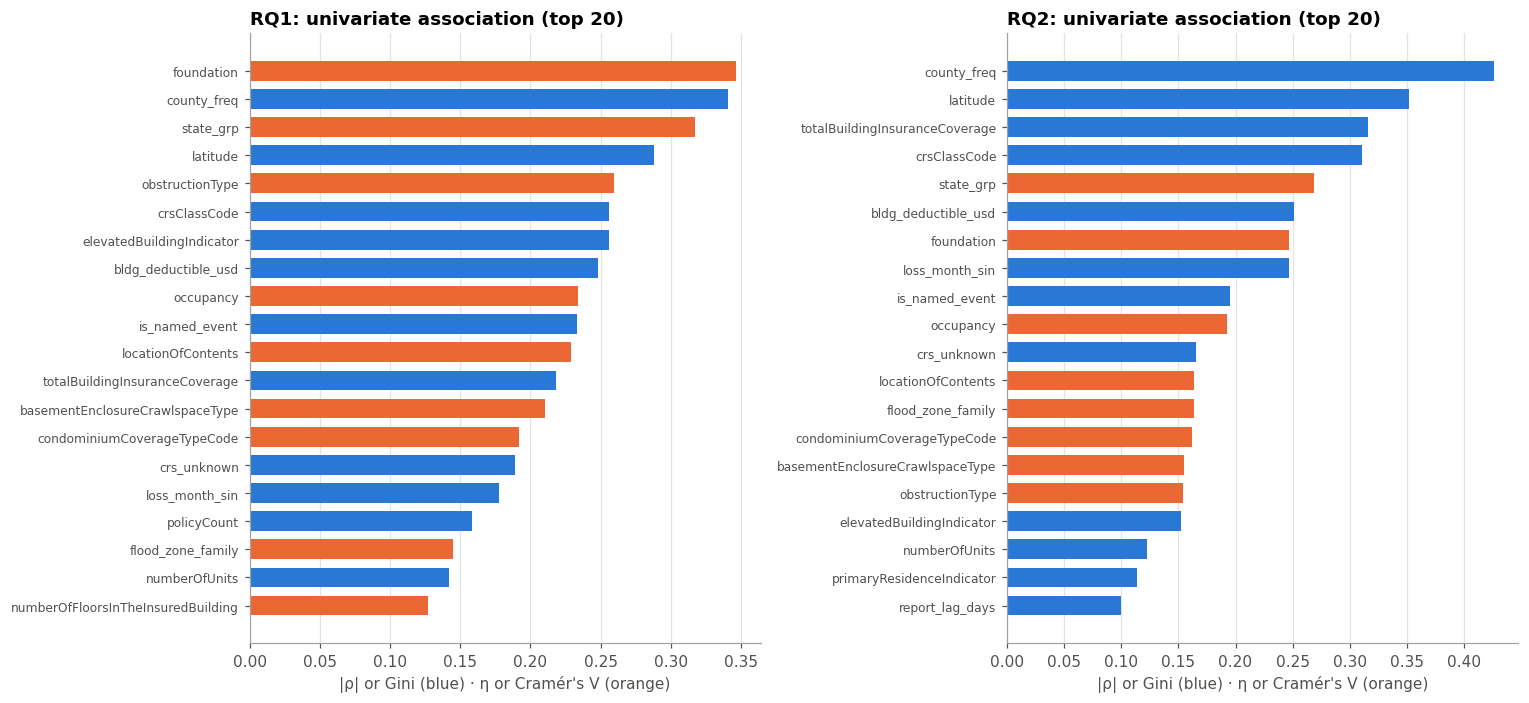

In [7]:
def eta(cat, y):
    df_ = pd.DataFrame({"c": cat, "y": y}); g = df_.groupby("c")["y"]
    return np.sqrt((g.count() * (g.mean() - df_["y"].mean()) ** 2).sum() / ((df_["y"] - df_["y"].mean()) ** 2).sum())

uni = {}
for key, R in RQ.items():
    idx = np.where(R["rows"] & ~TEST)[0]                                                # all selection years (2020–2023)
    idx = rng.choice(idx, min(80000, len(idx)), replace=False)
    y = R["y"][idx]; out = {}
    for c in TIER_A:
        x = XO[c].values[idx]
        if c in NOMINAL:
            out[c] = eta(x, y) if R["kind"] == "reg" else cramers_v(x, y)
        else:
            out[c] = abs(stats.spearmanr(x, y).statistic) if R["kind"] == "reg" else abs(2 * roc_auc_score(y, x) - 1)
    uni[key] = pd.Series(out)
uni = pd.DataFrame(uni)

fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
for a, key in zip(ax, RQ):
    s = uni[key].sort_values().tail(20)
    a.barh(s.index, s.values, color=[C[1] if c in NOMINAL else C[0] for c in s.index], height=0.7)
    a.tick_params(axis="y", labelsize=8); a.grid(axis="y", visible=False)
    a.set(title=f"{key}: univariate association (top 20)", xlabel="|ρ| or Gini (blue) · η or Cramér's V (orange)")
plt.tight_layout(); savefig("univariate"); plt.show()

## 5. Filter 3: mutual information
Mutual information measures **any** dependence, linear or not, between a feature and the target (0 = independent). It is estimated with k-nearest neighbours. Nominal, ordinal-code and binary columns are declared discrete so they are not treated as continuous distances. The estimate uses a 60k-row sample of the selection years.

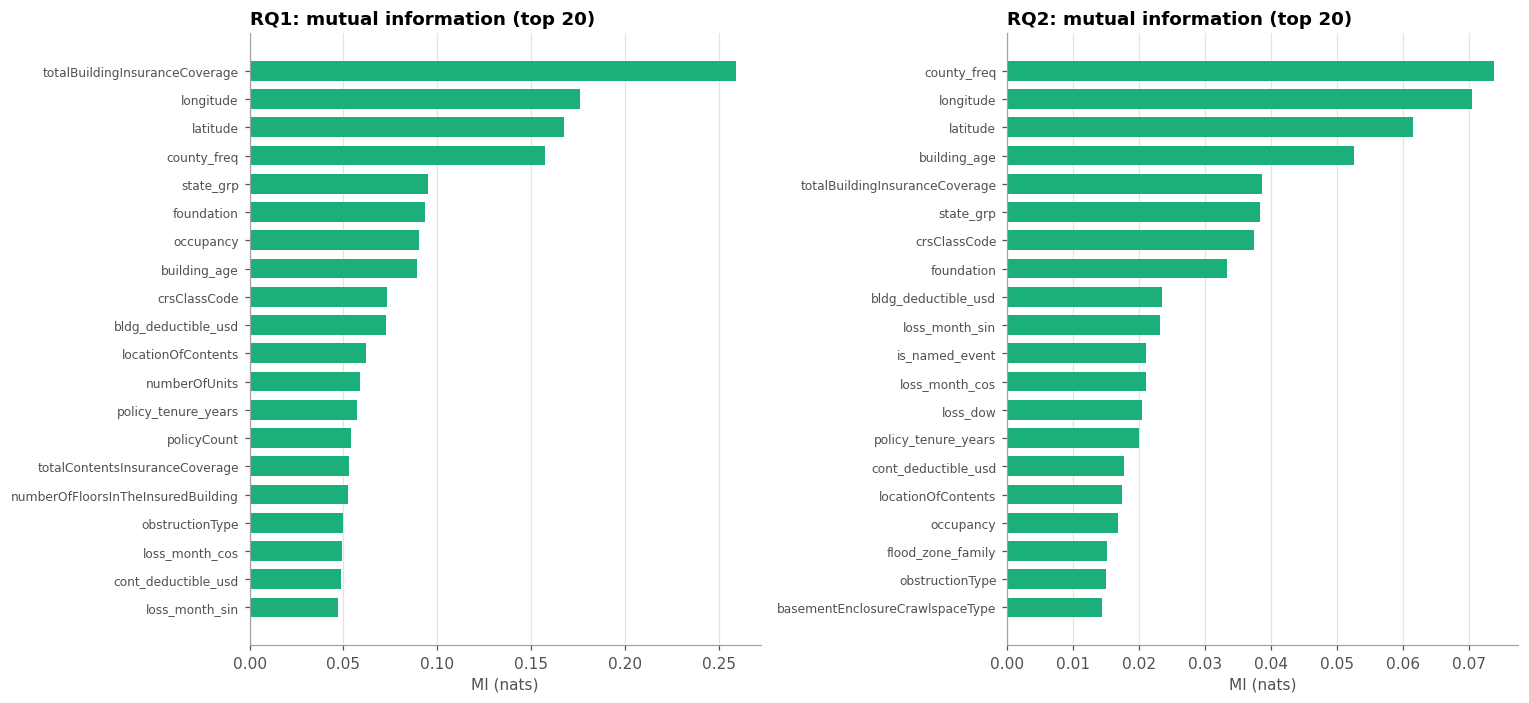

In [8]:
discrete = np.array([c in NOMINAL or c in BINARY or c in ORDINAL or c == "loss_dow" for c in TIER_A])
mi = {}
for key, R in RQ.items():
    idx = np.where(R["rows"] & ~TEST)[0]; idx = rng.choice(idx, min(60000, len(idx)), replace=False)
    f = mutual_info_regression if R["kind"] == "reg" else mutual_info_classif
    mi[key] = pd.Series(f(XO.iloc[idx][TIER_A].values, R["y"][idx], discrete_features=discrete, random_state=SEED), index=TIER_A)
mi = pd.DataFrame(mi)
fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
for a, key in zip(ax, RQ):
    s = mi[key].sort_values().tail(20)
    a.barh(s.index, s.values, color=C[2], height=0.7); a.tick_params(axis="y", labelsize=8); a.grid(axis="y", visible=False)
    a.set(title=f"{key}: mutual information (top 20)", xlabel="MI (nats)")
plt.tight_layout(); savefig("mutual_information"); plt.show()

## 6. Embedded and model-agnostic methods
### 6.1 L1 regularisation (Lasso for RQ1, L1-logistic for RQ2)
An L1 penalty pushes weak coefficients to **exactly zero**, so the model performs selection while it fits. The penalty strength is chosen by cross-validation. Because each nominal feature has several dummy columns, a feature's importance is the **sum of |coefficient|** over its dummies (all columns are standardised, so the sizes are comparable). The Lasso *path* shows the order in which features enter as the penalty is relaxed. Early entry means strong signal.

Lasso alpha = 0.000521: 40 of 44 features keep a non-zero coefficient
L1-logistic C = 0.05179: 41 of 44 features keep a non-zero coefficient


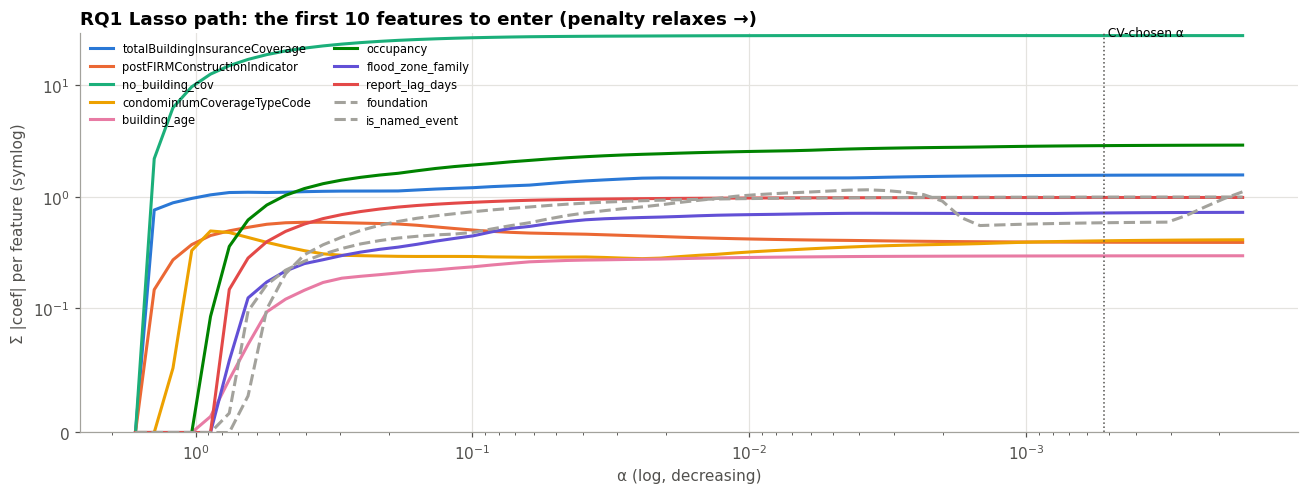

In [9]:
l1 = {}; l1_nonzero = {}
idx1 = rng.choice(np.where(RQ["RQ1"]["rows"] & ~TEST)[0], 60000, replace=False)
las = LassoCV(cv=5, n_alphas=40, random_state=SEED, n_jobs=-1).fit(XL.iloc[idx1], RQ["RQ1"]["y"][idx1])
coef1 = pd.Series(np.abs(las.coef_), index=XL.columns)
idx2 = rng.choice(np.where(RQ["RQ2"]["rows"] & ~TEST)[0], 60000, replace=False)
lr = LogisticRegressionCV(Cs=np.logspace(-3, 0, 8), penalty="l1", solver="liblinear", cv=4, scoring="average_precision",
                          class_weight="balanced", max_iter=400, random_state=SEED, n_jobs=-1).fit(XL.iloc[idx2], RQ["RQ2"]["y"][idx2])
coef2 = pd.Series(np.abs(lr.coef_.ravel()), index=XL.columns)
for key, cf in [("RQ1", coef1), ("RQ2", coef2)]:
    agg = cf.groupby(cf.index.map(lin_owner)).sum().reindex(TIER_A).fillna(0)
    l1[key] = agg; l1_nonzero[key] = int((agg > 0).sum())
l1 = pd.DataFrame(l1)
print(f"Lasso alpha = {las.alpha_:.4g}: {l1_nonzero['RQ1']} of {len(TIER_A)} features keep a non-zero coefficient")
print(f"L1-logistic C = {lr.C_[0]:.4g}: {l1_nonzero['RQ2']} of {len(TIER_A)} features keep a non-zero coefficient")

alphas, coefs, _ = lasso_path(XL.iloc[idx1[:30000]].values, RQ["RQ1"]["y"][idx1[:30000]], n_alphas=60, eps=1e-4)
owner = np.array([lin_owner[c] for c in XL.columns])
feat_path = pd.DataFrame(np.abs(coefs), index=owner).groupby(level=0).sum()
entry = feat_path.gt(1e-6).idxmax(axis=1).map(lambda j: alphas[j])          # largest alpha at which each feature becomes active
first10 = entry.sort_values(ascending=False).head(10).index
fig, ax = plt.subplots(figsize=(12, 4.6))
for i, f in enumerate(first10):
    ax.plot(alphas, feat_path.loc[f], lw=2, color=C[i % 8] if i < 8 else GRAY, ls="-" if i < 8 else "--", label=f)
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=0.1); ax.set_ylim(bottom=0); ax.invert_xaxis(); ax.axvline(las.alpha_, color=INK2, ls=":", lw=1); ax.text(las.alpha_, ax.get_ylim()[1] * 0.95, " CV-chosen α", fontsize=8)
ax.set(title="RQ1 Lasso path: the first 10 features to enter (penalty relaxes →)", xlabel="α (log, decreasing)", ylabel="Σ |coef| per feature (symlog)")
ax.legend(fontsize=7.5, ncol=2, loc="upper left"); plt.tight_layout(); savefig("lasso_path"); plt.show()

**A warning from the path.** `no_building_cov` gets by far the largest coefficient. Among *paid building claims* it is set on only 68 rows: building payments on policies with **no building coverage**, which is impossible and already flagged as "payment above coverage" in the EDA. A rare, standardised dummy that isolates a handful of extreme rows earns a huge linear weight. This is why the L1 vote is only one of six, and why `no_building_cov` ends up **not selected** for RQ1 (no reliable signal in the tree-based checks).

### 6.2 Random-forest impurity importance
How much each feature reduces impurity (variance / Gini), summed over all splits. It is fast and captures non-linearity, but it is **biased towards high-cardinality and continuous features**, which have more split points. That bias is why it is only one vote of several.

### 6.3 Permutation importance on the validation year (2023)
A gradient-boosting model is trained on **2020–2022**. Then each feature is shuffled in turn on **2023** and the drop in score is measured. This is the most direct answer to "does the model *need* this feature on data it hasn't seen?". A feature whose drop is within 2 SD of zero (over 5 repeats) carries no reliable signal.

validation-year (2023) score with all tier-A features: {'RQ1': {'R²': 0.129, 'RMSE (log)': np.float64(1.286), 'MAE ($)': 36880.204}, 'RQ2': {'PR-AUC': 0.425, 'ROC-AUC': 0.753, 'base rate': np.float64(0.181)}}


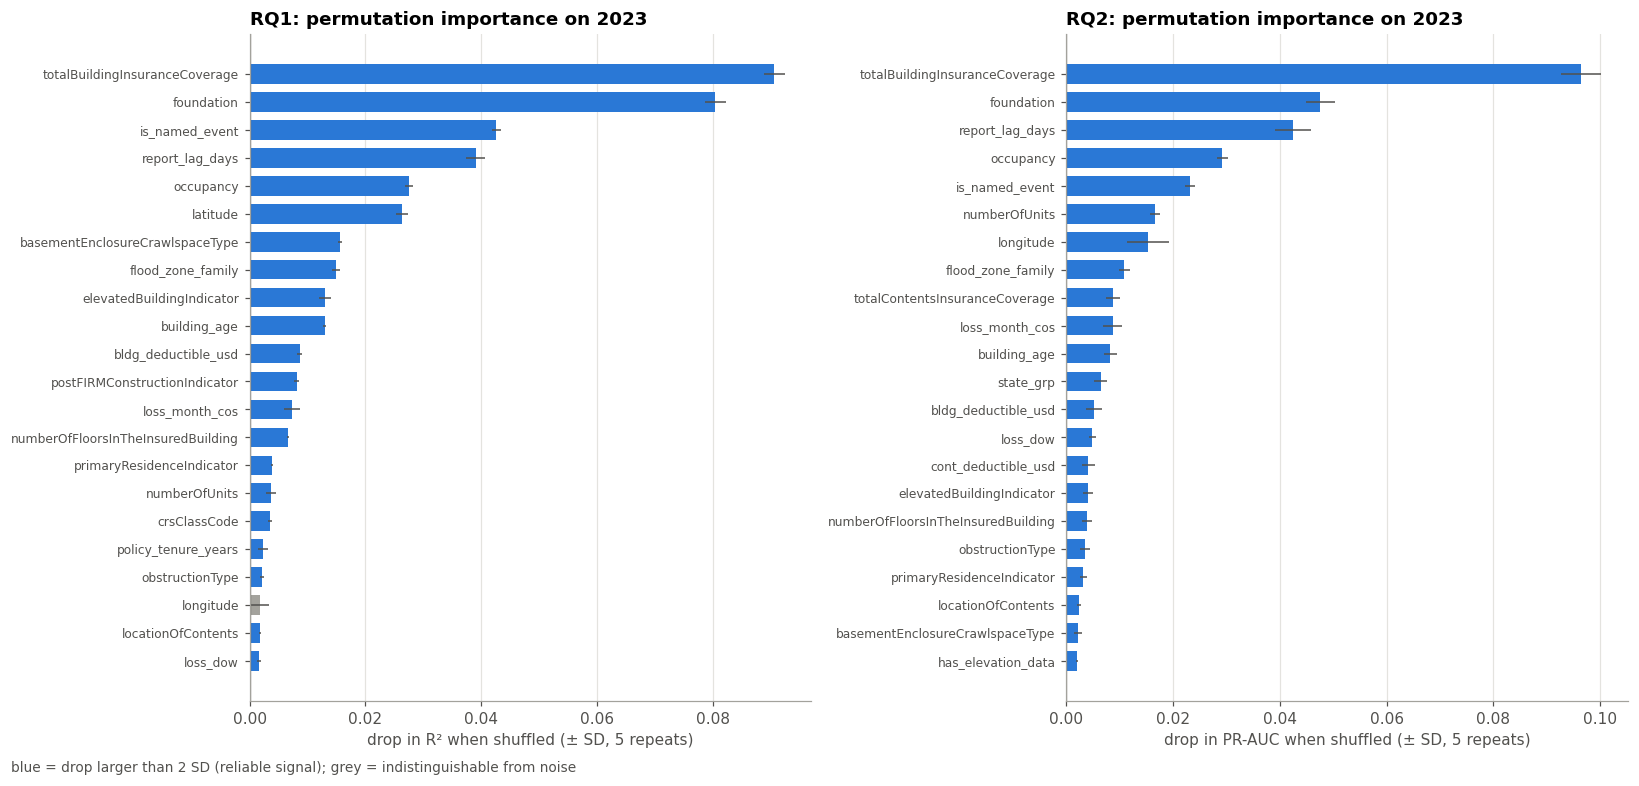

In [10]:
rf_imp, perm, perm_sd, val_scores = {}, {}, {}, {}
cat_idx_A = [TIER_A.index(c) for c in NOMINAL]
for key, R in RQ.items():
    tr = np.where(R["rows"] & FIT)[0]; va = np.where(R["rows"] & VAL)[0]
    tr_s = rng.choice(tr, min(100000, len(tr)), replace=False)
    RF = RandomForestRegressor if R["kind"] == "reg" else RandomForestClassifier
    kw = {} if R["kind"] == "reg" else {"class_weight": "balanced_subsample"}
    rf = RF(n_estimators=150, min_samples_leaf=25, max_features=0.4, n_jobs=-1, random_state=SEED, **kw).fit(XO.iloc[tr_s][TIER_A], R["y"][tr_s])
    rf_imp[key] = pd.Series(rf.feature_importances_, index=TIER_A)
    m = hgb(R["kind"], cat_idx_A).fit(XO.iloc[tr][TIER_A], R["y"][tr])
    scoring = "r2" if R["kind"] == "reg" else "average_precision"
    p = m.predict(XO.iloc[va][TIER_A]) if R["kind"] == "reg" else m.predict_proba(XO.iloc[va][TIER_A])[:, 1]
    val_scores[key] = score(R["kind"], R["y"][va], p)
    pi = permutation_importance(m, XO.iloc[va][TIER_A], R["y"][va], scoring=scoring, n_repeats=5, random_state=SEED, n_jobs=-1)
    perm[key] = pd.Series(pi.importances_mean, index=TIER_A); perm_sd[key] = pd.Series(pi.importances_std, index=TIER_A)
rf_imp, perm, perm_sd = pd.DataFrame(rf_imp), pd.DataFrame(perm), pd.DataFrame(perm_sd)
print("validation-year (2023) score with all tier-A features:", {k: {m_: round(v, 3) for m_, v in s.items()} for k, s in val_scores.items()})

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
for a, key in zip(ax, RQ):
    s = perm[key].sort_values().tail(22); e = perm_sd[key][s.index]
    signal = s > 2 * e
    a.barh(s.index, s.values, xerr=e.values, color=[C[0] if g else GRAY for g in signal], height=0.7, error_kw=dict(ecolor=INK2, lw=1))
    a.axvline(0, color=INK2, lw=0.8); a.tick_params(axis="y", labelsize=8); a.grid(axis="y", visible=False)
    a.set(title=f"{key}: permutation importance on 2023", xlabel=f"drop in {'R²' if key == 'RQ1' else 'PR-AUC'} when shuffled (± SD, 5 repeats)")
fig.text(0.01, -0.01, "blue = drop larger than 2 SD (reliable signal); grey = indistinguishable from noise", fontsize=9, color=INK2)
plt.tight_layout(); savefig("permutation_importance"); plt.show()

### 6.4 Wrapper: recursive feature elimination with year-grouped CV (RFECV)
RFECV fits a model, removes the least important features, refits, and records the cross-validated score at every subset size. Its CV folds are **whole loss years** (leave-one-year-out over 2020–2023), so the curve shows how well a subset **generalises to a year it has not seen**. A random-forest model is used on a 40k-row sample to keep it tractable.

RQ1: RFECV keeps 34 features (33s)


RQ2: RFECV keeps 42 features (38s)


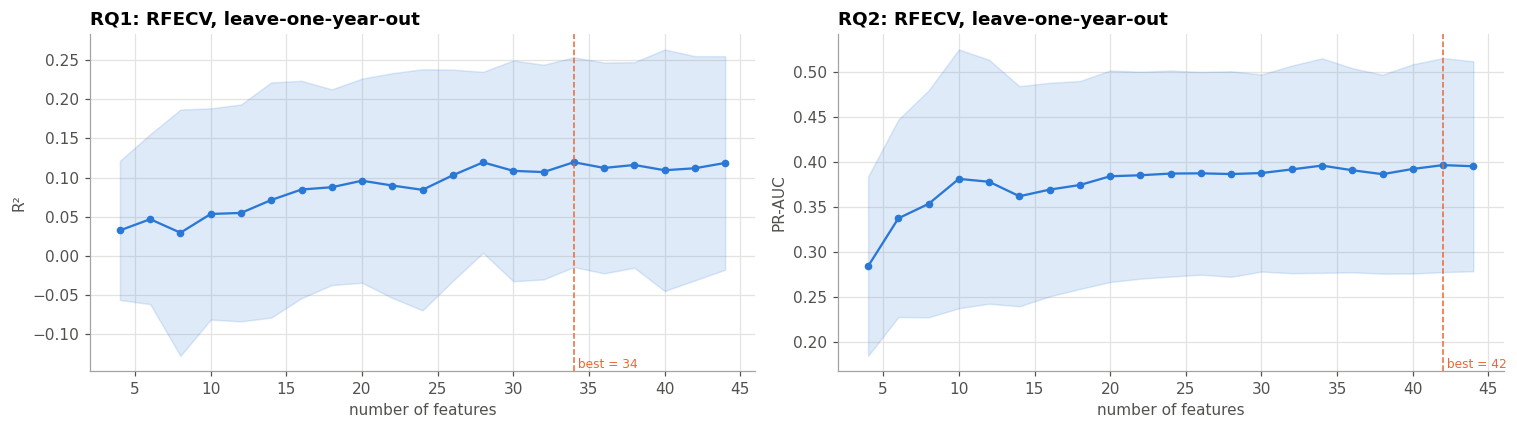

In [11]:
rfecv_res = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, key in zip(ax, RQ):
    R = RQ[key]
    idx = np.where(R["rows"] & ~TEST)[0]; idx = rng.choice(idx, min(40000, len(idx)), replace=False)
    RF = RandomForestRegressor if R["kind"] == "reg" else RandomForestClassifier
    kw = {} if R["kind"] == "reg" else {"class_weight": "balanced_subsample"}
    est = RF(n_estimators=60, min_samples_leaf=25, max_features=0.4, n_jobs=-1, random_state=SEED, **kw)
    t0 = time.time()
    sel = RFECV(est, step=2, min_features_to_select=4, cv=GroupKFold(n_splits=4), scoring="r2" if R["kind"] == "reg" else "average_precision",
                n_jobs=1).fit(XO.iloc[idx][TIER_A], R["y"][idx], groups=year[idx])
    res = sel.cv_results_; nfeat = res["n_features"]
    rfecv_res[key] = dict(support=pd.Series(sel.support_, index=TIER_A), ranking=pd.Series(sel.ranking_, index=TIER_A), n=sel.n_features_)
    a.plot(nfeat, res["mean_test_score"], "-o", ms=4, color=C[0])
    a.fill_between(nfeat, res["mean_test_score"] - res["std_test_score"], res["mean_test_score"] + res["std_test_score"], color=C[0], alpha=0.15)
    a.axvline(sel.n_features_, color=C[1], ls="--", lw=1); a.text(sel.n_features_, a.get_ylim()[0], f" best = {sel.n_features_}", color=C[1], fontsize=8, va="bottom")
    a.set(title=f"{key}: RFECV, leave-one-year-out", xlabel="number of features", ylabel="R²" if key == "RQ1" else "PR-AUC")
    print(f"{key}: RFECV keeps {sel.n_features_} features ({time.time() - t0:.0f}s)")
plt.tight_layout(); savefig("rfecv"); plt.show()

**Reading the RFECV curves.** Both curves rise over the first 10–20 features and then **plateau**. The "best" sizes (34 for RQ1, 42 for RQ2) sit on that plateau, within a fraction of the band. The shaded **±1 SD band across loss years is far wider than any difference between subset sizes**: how well a model does depends much more on *which year (which storms)* it is tested on than on how many features it has. That is why RFECV's own choice is not used as the final list. It is one vote in the consensus, where a feature it drops counts against it.

## 7. Consensus: combine the votes, then prune redundancy
Each method ranks the 44 candidates (1 = most important). A feature's **consensus rank** is the mean of its percentile ranks over the six methods: univariate, MI, L1, RF impurity, permutation, RFECV. The final list keeps a feature when:

0. it is not near-constant (3.1);
1. its consensus rank is in the **top half**, **and** it shows **reliable signal** in at least one model-based check (permutation drop > 2 SD, or kept by RFECV), **and**
2. it is **not redundant** with a better-ranked feature already kept: |ρ| ≥ 0.8 or Cramér's V ≥ 0.8. Every pair is taken from the tables computed in Section 3.2. None is typed by hand.

binary × nominal pairs treated as redundant (computed in Section 3.2): [('is_rr2', 'rating_group'), ('is_rr2', 'foundation'), ('no_contents_cov', 'locationOfContents'), ('obstructionType', 'elevatedBuildingIndicator'), ('bldg_deductible_unknown', 'rating_group')]


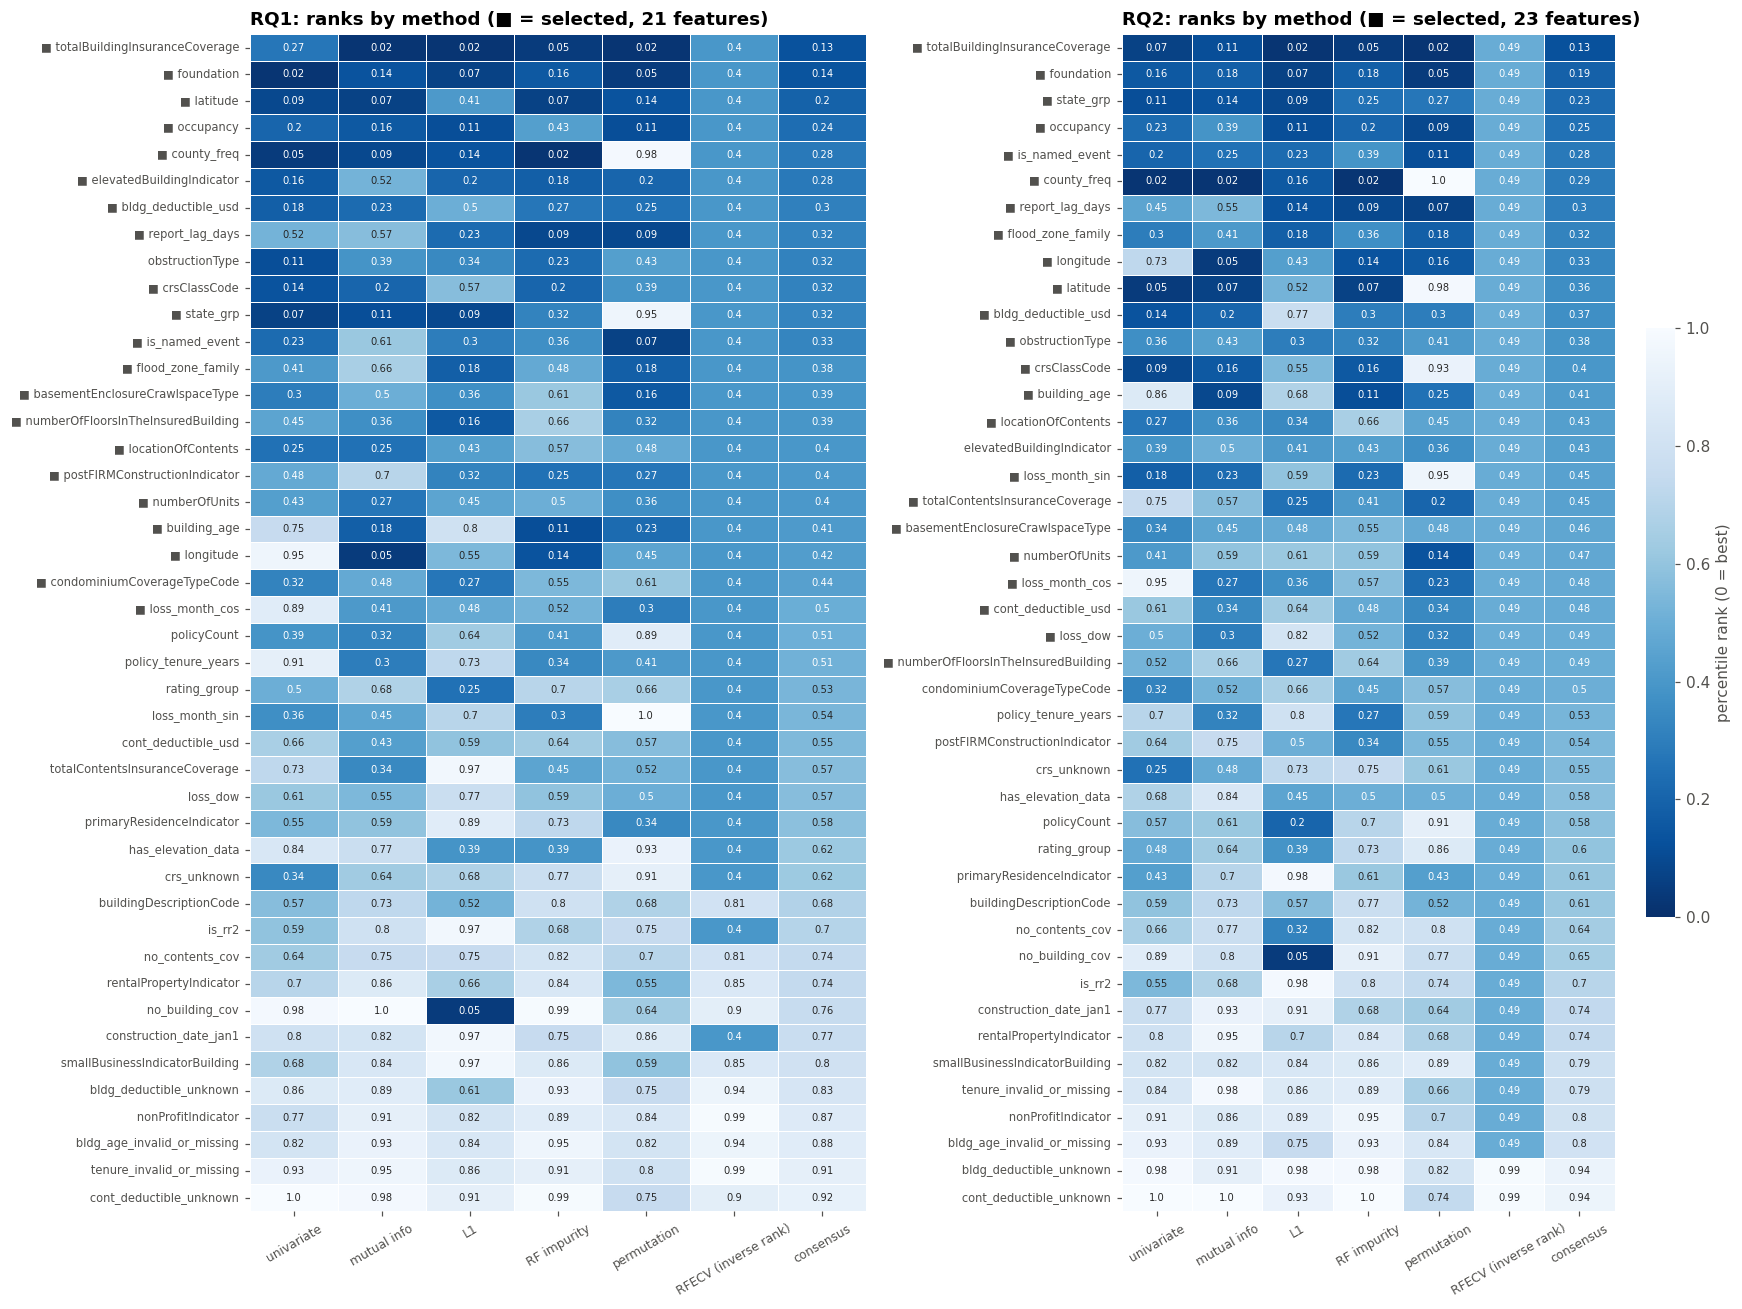

RQ1 selected (21): ['totalBuildingInsuranceCoverage', 'foundation', 'latitude', 'occupancy', 'county_freq', 'elevatedBuildingIndicator', 'bldg_deductible_usd', 'report_lag_days', 'crsClassCode', 'state_grp', 'is_named_event', 'flood_zone_family', 'basementEnclosureCrawlspaceType', 'numberOfFloorsInTheInsuredBuilding', 'locationOfContents', 'postFIRMConstructionIndicator', 'numberOfUnits', 'building_age', 'longitude', 'condominiumCoverageTypeCode', 'loss_month_cos']
RQ2 selected (23): ['totalBuildingInsuranceCoverage', 'foundation', 'state_grp', 'occupancy', 'is_named_event', 'county_freq', 'report_lag_days', 'flood_zone_family', 'longitude', 'latitude', 'bldg_deductible_usd', 'obstructionType', 'crsClassCode', 'building_age', 'locationOfContents', 'loss_month_sin', 'totalContentsInsuranceCoverage', 'basementEnclosureCrawlspaceType', 'numberOfUnits', 'loss_month_cos', 'cont_deductible_usd', 'loss_dow', 'numberOfFloorsInTheInsuredBuilding']


In [12]:
REDUNDANT_CUT = 0.8          # one cut, used for every kind of pair
BIN_NOM_PAIRS = {frozenset([r.binary, r.nominal]) for r in bin_nom.itertuples() if r.V >= REDUNDANT_CUT}
print("binary × nominal pairs treated as redundant (computed in Section 3.2):", [tuple(p_) for p_ in BIN_NOM_PAIRS])
def redundant(a, b):
    if frozenset([a, b]) in BIN_NOM_PAIRS: return True
    if a in rho.index and b in rho.index: return abs(rho.loc[a, b]) >= REDUNDANT_CUT
    if a in cv_nom.index and b in cv_nom.index: return cv_nom.loc[a, b] >= REDUNDANT_CUT
    return False

selected, rank_tables = {}, {}
for key in RQ:
    votes = pd.DataFrame({"univariate": uni[key], "mutual info": mi[key], "L1": l1[key], "RF impurity": rf_imp[key],
                          "permutation": perm[key], "RFECV (inverse rank)": 1 / rfecv_res[key]["ranking"]})
    pr = votes.rank(ascending=False, pct=True)
    pr["consensus"] = pr.mean(axis=1)
    pr["perm signal"] = (perm[key] > 2 * perm_sd[key]) & (perm[key] > 0)
    pr["RFECV kept"] = rfecv_res[key]["support"]
    pr = pr.sort_values("consensus")
    keep, why_out = [], {}
    for f, r in pr.iterrows():
        if f in NEAR_CONST: why_out[f] = "near-constant in training years (≥ 99.5%)"; continue
        if r["consensus"] > 0.5: why_out[f] = "consensus rank in bottom half"; continue
        if not (r["perm signal"] or r["RFECV kept"]): why_out[f] = "no reliable signal (permutation ≈ 0 and dropped by RFECV)"; continue
        clash = next((k for k in keep if redundant(f, k)), None)
        if clash: why_out[f] = f"redundant with {clash}"; continue
        keep.append(f)
    pr["selected"] = pr.index.isin(keep); pr["reason if dropped"] = pd.Series(why_out)
    selected[key] = keep; rank_tables[key] = pr

fig, axes = plt.subplots(1, 2, figsize=(16, 12))
for a, key in zip(axes, RQ):
    pr = rank_tables[key]
    H = pr[["univariate", "mutual info", "L1", "RF impurity", "permutation", "RFECV (inverse rank)", "consensus"]]
    sns.heatmap(H, cmap="Blues_r", vmin=0, vmax=1, ax=a, cbar=a is axes[-1], cbar_kws={"label": "percentile rank (0 = best)", "shrink": 0.5},
                linewidths=0.5, linecolor="white", annot=H.round(2), fmt="", annot_kws={"size": 6.5})
    a.set_yticklabels([("■ " if pr.loc[t.get_text(), "selected"] else "   ") + t.get_text() for t in a.get_yticklabels()], fontsize=7.5)
    a.set_title(f"{key}: ranks by method (■ = selected, {len(selected[key])} features)"); a.tick_params(axis="x", labelsize=8, rotation=30); a.grid(False)
plt.tight_layout(); savefig("consensus"); plt.show()
for key in RQ: print(f"{key} selected ({len(selected[key])}):", selected[key])

In [13]:
key = "RQ1"
show = ["consensus", "perm signal", "RFECV kept", "selected", "reason if dropped"]
display(rank_tables["RQ1"][show].style.format({"consensus": "{:.2f}"}).set_caption("RQ1: decision per feature"))
display(rank_tables["RQ2"][show].style.format({"consensus": "{:.2f}"}).set_caption("RQ2: decision per feature"))

,consensus,perm signal,RFECV kept,selected,reason if dropped
totalBuildingInsuranceCoverage,0.13,True,True,True,nan
foundation,0.14,True,True,True,nan
latitude,0.20,True,True,True,nan
occupancy,0.24,True,True,True,nan
county_freq,0.28,False,True,True,nan
elevatedBuildingIndicator,0.28,True,True,True,nan
bldg_deductible_usd,0.30,True,True,True,nan
report_lag_days,0.32,True,True,True,nan
obstructionType,0.32,True,True,False,redundant with elevatedBuildingIndicator
crsClassCode,0.32,True,True,True,nan


,consensus,perm signal,RFECV kept,selected,reason if dropped
totalBuildingInsuranceCoverage,0.13,True,True,True,nan
foundation,0.19,True,True,True,nan
state_grp,0.23,True,True,True,nan
occupancy,0.25,True,True,True,nan
is_named_event,0.28,True,True,True,nan
county_freq,0.29,False,True,True,nan
report_lag_days,0.30,True,True,True,nan
flood_zone_family,0.32,True,True,True,nan
longitude,0.33,True,True,True,nan
latitude,0.36,False,True,True,nan


## 8. Final check on the untouched test years (2024–25)
Now, and only now, the test years are used. Each model is trained on **all of 2020–2023** and scored on 2024–25 with three feature sets: **all 44 tier-A features**, the **selected subset**, and the **top 5** by consensus. A non-linear model (gradient boosting) and a linear model (Ridge / L2-logistic on the linear design) are both run. Selection can help one and not the other.

RQ,features,n,model,R²,RMSE (log),MAE ($),PR-AUC,ROC-AUC,base rate
RQ1,all tier A,44,gradient boosting,0.326,1.217,"$62,300",,,
RQ1,all tier A,44,linear (Ridge / logistic),0.278,1.260,"$61,612",,,
RQ1,selected,21,gradient boosting,0.329,1.215,"$61,348",,,
RQ1,selected,21,linear (Ridge / logistic),0.260,1.276,"$62,431",,,
RQ1,top 5 consensus,5,gradient boosting,0.177,1.345,"$67,109",,,
RQ1,top 5 consensus,5,linear (Ridge / logistic),0.125,1.387,"$68,374",,,
RQ2,all tier A,44,gradient boosting,,,,0.670,0.834,36.2%
RQ2,all tier A,44,linear (Ridge / logistic),,,,0.636,0.805,36.2%
RQ2,selected,23,gradient boosting,,,,0.666,0.832,36.2%
RQ2,selected,23,linear (Ridge / logistic),,,,0.624,0.797,36.2%


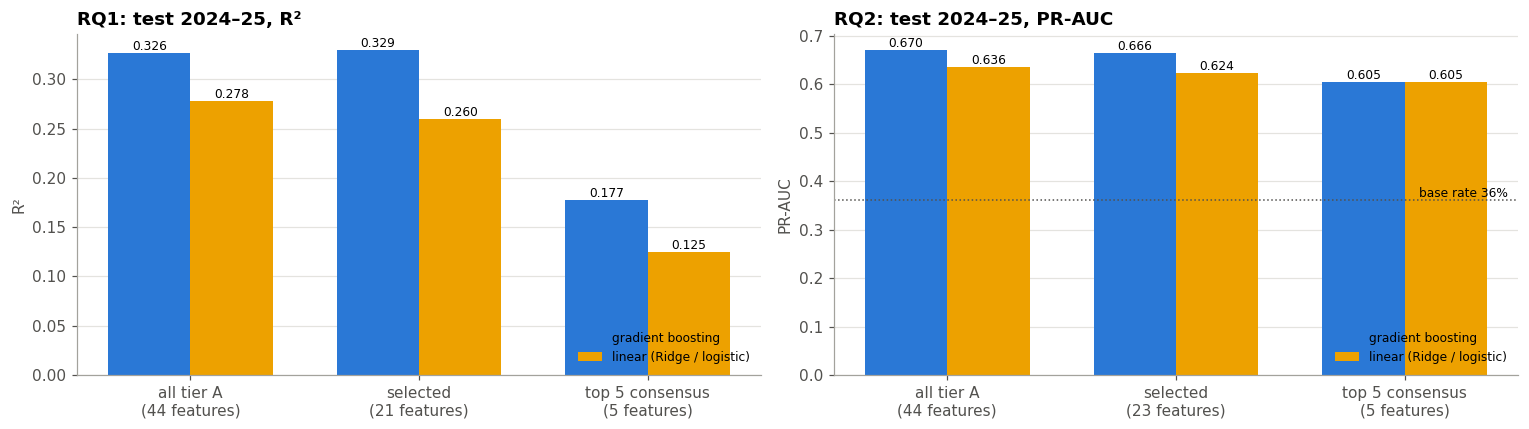

In [14]:
def linear_cols(feats): return [c for c in XL.columns if lin_owner[c] in feats]
final_rows = []
for key, R in RQ.items():
    tr, te = R["rows"] & ~TEST, R["rows"] & TEST
    for sname, feats in [("all tier A", TIER_A), ("selected", selected[key]), ("top 5 consensus", rank_tables[key].index[:5].tolist())]:
        cat_idx = [feats.index(c) for c in feats if c in NOMINAL]
        m = hgb(R["kind"], cat_idx).fit(XO.loc[tr, feats], R["y"][tr])
        p = m.predict(XO.loc[te, feats]) if R["kind"] == "reg" else m.predict_proba(XO.loc[te, feats])[:, 1]
        final_rows.append({"RQ": key, "features": sname, "n": len(feats), "model": "gradient boosting", **score(R["kind"], R["y"][te], p)})
        lc = linear_cols(feats)
        lm = RidgeCV(alphas=np.logspace(-2, 3, 12)) if R["kind"] == "reg" else LogisticRegression(C=1.0, class_weight="balanced", max_iter=500)
        lm.fit(XL.loc[tr, lc], R["y"][tr])
        p = lm.predict(XL.loc[te, lc]) if R["kind"] == "reg" else lm.predict_proba(XL.loc[te, lc])[:, 1]
        final_rows.append({"RQ": key, "features": sname, "n": len(feats), "model": "linear (Ridge / logistic)", **score(R["kind"], R["y"][te], p)})
final = pd.DataFrame(final_rows)
display(final.style.format({"R²": "{:.3f}", "RMSE (log)": "{:.3f}", "MAE ($)": "${:,.0f}", "PR-AUC": "{:.3f}", "ROC-AUC": "{:.3f}", "base rate": "{:.1%}"}, na_rep="").hide(axis="index"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, key, met in [(ax[0], "RQ1", "R²"), (ax[1], "RQ2", "PR-AUC")]:
    t = final[final["RQ"] == key]
    piv = t.pivot(index="features", columns="model", values=met).loc[["all tier A", "selected", "top 5 consensus"]]
    nlab = t.drop_duplicates("features").set_index("features")["n"]
    x = np.arange(len(piv)); w = 0.36
    for i, (mname, colr) in enumerate(zip(piv.columns, [C[0], C[3]])):
        a.bar(x + (i - 0.5) * w, piv[mname], w, color=colr, label=mname)
        for xi, v in zip(x, piv[mname]): a.text(xi + (i - 0.5) * w, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    if key == "RQ2":
        br = t["base rate"].iloc[0]; a.axhline(br, color=INK2, ls=":", lw=1); a.text(2.45, br, f"base rate {br:.0%}", fontsize=8, ha="right", va="bottom")
    a.set_xticks(x); a.set_xticklabels([f"{f}\n({nlab[f]} features)" for f in piv.index]); a.grid(axis="x", visible=False)
    a.set(title=f"{key}: test 2024–25, {met}", ylabel=met); a.legend(fontsize=8, loc="lower right")
plt.tight_layout(); savefig("final_check"); plt.show()

## 9. RQ3: choosing variables for clustering (no target)
Clustering has no label, so the supervised votes above do not apply. The variables must instead:

1. describe **flood-risk profile** (the proposal's question: zone, elevation, construction, geography), and must **not** include outcomes. Damage and payment are used *afterwards* to validate the clusters, never to form them;
2. be **non-redundant**, because k-means and PCA count a duplicated idea twice;
3. be **informative**: enough spread after scaling.

`elevationDifference` is the most direct risk number but is recorded for only about a third of claims. RQ3 can therefore be run on the **Elevation-Certificate subset** (with it) or on **all claims** (without it). Both lists are given below.

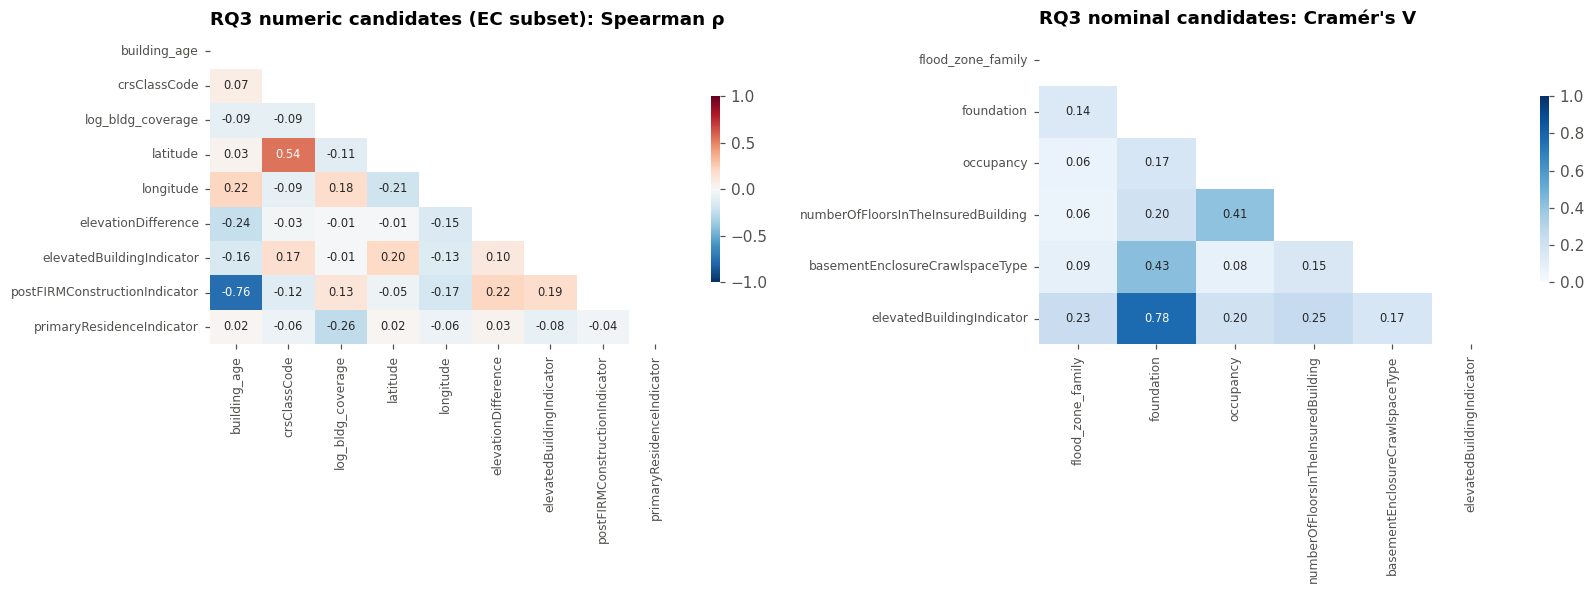

claims with elevation data: 34% (94,449)


In [15]:
RQ3_CANDIDATES = ["flood_zone_family", "foundation", "elevatedBuildingIndicator", "postFIRMConstructionIndicator", "building_age",
                  "numberOfFloorsInTheInsuredBuilding", "occupancy", "crsClassCode", "log_bldg_coverage", "latitude", "longitude",
                  "basementEnclosureCrawlspaceType", "primaryResidenceIndicator", "elevationDifference"]
ec = d["has_elevation_data"].eq(1).values
num3 = ["building_age", "crsClassCode", "log_bldg_coverage", "latitude", "longitude", "elevationDifference",
        "elevatedBuildingIndicator", "postFIRMConstructionIndicator", "primaryResidenceIndicator"]
r3 = d.loc[ec & ~TEST, num3].sample(40000, random_state=SEED).astype(float).corr(method="spearman")
nom3 = ["flood_zone_family", "foundation", "occupancy", "numberOfFloorsInTheInsuredBuilding", "basementEnclosureCrawlspaceType"]
s3 = d.loc[~TEST, nom3 + ["elevatedBuildingIndicator"]].sample(40000, random_state=SEED).astype(str)
v3 = pd.DataFrame({a: {b: (1.0 if a == b else cramers_v(s3[a], s3[b])) for b in s3.columns} for a in s3.columns})
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(r3, mask=np.triu(np.ones_like(r3, dtype=bool)), cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, ax=ax[0], cbar_kws={"shrink": 0.6}); ax[0].set_title("RQ3 numeric candidates (EC subset): Spearman ρ"); ax[0].grid(False)
sns.heatmap(v3, mask=np.triu(np.ones_like(v3, dtype=bool)), cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7.5},
            ax=ax[1], cbar_kws={"shrink": 0.6}); ax[1].set_title("RQ3 nominal candidates: Cramér's V"); ax[1].grid(False)
for a in ax: a.tick_params(labelsize=8)
plt.tight_layout(); savefig("rq3_candidates"); plt.show()
print(f"claims with elevation data: {ec.mean():.0%} ({ec.sum():,})")

**RQ3 decision**
* **Kept:** `flood_zone_family`, `foundation` (it subsumes the elevated flag, so `elevatedBuildingIndicator` is dropped as redundant, V ≈ 0.78), `building_age`, `numberOfFloorsInTheInsuredBuilding`, `occupancy`, `crsClassCode`, `log_bldg_coverage`, and `elevationDifference` on the EC subset.
* **`postFIRMConstructionIndicator` is dropped** for clustering: ρ ≈ −0.76 with building age. Keeping both would make "old vs new" count twice in the distance. Building age is the more detailed of the two.
* **Geography.** `latitude`/`longitude` are kept **out of the clustering inputs**. Otherwise k-means mostly rediscovers "Florida vs Louisiana vs the Northeast", and the profiles stop being about the *building*. Geography is used afterwards to describe the clusters, like damage and payment. (CRS class already carries much of the location signal, ρ ≈ 0.54 with latitude on the EC subset.)
* **Dropped:** `basementEnclosureCrawlspaceType` (49% "unknown", V ≈ 0.43 with foundation) and `primaryResidenceIndicator` (a use attribute already carried by occupancy, V ≈ 0.63 in the EDA association matrix).
* **Preprocessing for k-means and PCA:** one-hot the nominal columns, then StandardScaler (fit on train). The mixed types also make Gower distance or k-prototypes worth comparing in Module 4/5.

In [16]:
RQ3_SELECTED = {"all claims": ["flood_zone_family", "foundation", "building_age",
                               "numberOfFloorsInTheInsuredBuilding", "occupancy", "crsClassCode", "log_bldg_coverage"]}
RQ3_SELECTED["elevation-certificate subset"] = RQ3_SELECTED["all claims"] + ["elevationDifference"]

out = {"split": {"selection_fit": "2020-2022", "selection_validate": "2023", "test": "2024-2025"},
       "candidates_tier_A": TIER_A, "RQ1_selected": selected["RQ1"], "RQ2_selected": selected["RQ2"], "RQ3_selected": RQ3_SELECTED,
       "excluded_for_leakage": POST_B + ["log_bldg_damage"] + LEAK}
(EDA_OUT / "selected_features.json").write_text(json.dumps(out, indent=2))
for key in RQ: rank_tables[key].to_csv(EDA_OUT / f"feature_ranking_{key}.csv")
leak.to_csv(EDA_OUT / "fs_leakage_experiment.csv", index=False); final.to_csv(EDA_OUT / "fs_final_test_check.csv", index=False)
pd.DataFrame({"RQ1": pd.Series(selected["RQ1"]), "RQ2": pd.Series(selected["RQ2"]),
              "RQ3 (all claims)": pd.Series(RQ3_SELECTED["all claims"]), "RQ3 (EC subset)": pd.Series(RQ3_SELECTED["elevation-certificate subset"])}).fillna("")

,RQ1,RQ2,RQ3 (all claims),RQ3 (EC subset)
0,totalBuildingInsuranceCoverage,totalBuildingInsuranceCoverage,flood_zone_family,flood_zone_family
1,foundation,foundation,foundation,foundation
2,latitude,state_grp,building_age,building_age
3,occupancy,occupancy,numberOfFloorsInTheInsuredBuilding,numberOfFloorsInTheInsuredBuilding
4,county_freq,is_named_event,occupancy,occupancy
5,elevatedBuildingIndicator,county_freq,crsClassCode,crsClassCode
6,bldg_deductible_usd,report_lag_days,log_bldg_coverage,log_bldg_coverage
7,report_lag_days,flood_zone_family,,elevationDifference
8,crsClassCode,longitude,,
9,state_grp,latitude,,


## 10. Summary

**Split and candidates.** Selection used only the training years (fit 2020–2022, validate 2023, leave-one-year-out CV over 2020–2023). The 2024–25 test years were used once, for the final check. The candidates were the 44 pre-loss (tier-A) features from the EDA.

1. **Leakage is measured, not assumed.** On 2024–25, RQ1 R² goes from **0.33** with pre-loss features to **0.96** once the adjuster's damage figure and other inspection fields are added, and to **0.997** with payment outcomes. RQ2 PR-AUC goes from **0.67** to 0.81 to 0.995. The jump from A to B is the adjuster's damage figure "reading" the answer, and LEAK is trivial. Only tier A answers the early-triage question, so all selection is within tier A.
2. **Filters.** Two near-constant flags are removed. Redundancy sits in coverage ↔ its "no coverage" flag (VIF 14–52), building age ↔ post-FIRM (ρ ≈ −0.80), latitude ↔ county frequency, occupancy ↔ condo coverage type, and elevated ↔ foundation ↔ obstruction type (structural).
3. **The methods agree on the core.** Building coverage, foundation, occupancy, location (latitude / state / county frequency), named event, report lag, flood zone, deductible and CRS class rank high under univariate, MI, L1, RF, permutation and RFECV alike. Disagreements are informative. L1 over-weights `no_building_cov` because of 68 impossible rows (building payments with no building coverage). County frequency ranks high under impurity and MI but shows **no** permutation signal on 2023.
4. **Selected:** **21 features for RQ1** and **23 for RQ2** (lists in Section 8 and `outputs/selected_features.json`). Redundant pairs were taken from the computed tables, not typed by hand. For RQ1, `obstructionType` was dropped as almost a copy of `elevatedBuildingIndicator` (V = 0.98). For RQ2, the elevated flag was dropped in favour of the better-ranked `obstructionType`. `elevatedBuildingIndicator` ↔ `foundation` (V = 0.79) and `postFIRMConstructionIndicator` ↔ `building_age` (ρ = −0.796) sit just under the 0.8 cut, so both members survive. Trees are unaffected, but a linear model should keep only one of each.
5. **Did selection help? Honestly: it simplifies without hurting, and it does not improve accuracy.** On 2024–25 the gradient-boosting model with about half the features loses almost nothing: RQ1 R² **0.329 vs 0.326**, RQ2 PR-AUC **0.666 vs 0.670**. The linear models lose slightly more (RQ1 R² 0.260 vs 0.278). Cutting to the top 5 costs clearly more (RQ1 R² 0.18, RQ2 PR-AUC 0.61). The benefit is a smaller, explainable model with less redundancy, not a better score.
6. **What this does NOT show.** Pre-loss features explain only about a third of the variance in log payment. The validation year (2023, small storms) scored much lower (R² 0.13) than the test years. RFECV's year-to-year band is wider than any differences between subset sizes. Performance depends more on *which storms* a model meets than on the feature list. RQ2's base rate also jumps from 20% to 36% in the test years, so PR-AUC must be read against the base rate (0.67 vs 0.36).
7. **RQ3 (clustering).** No target is involved. The 7 profile variables (+ `elevationDifference` on the 34% Elevation-Certificate subset) were chosen for domain meaning and low redundancy. Geography and outcomes are kept out of the clustering inputs and used afterwards to describe and validate the clusters.